# SUIM exploration

Check image sizes, mask quality, class balance, and examples before training.
Use the project's .venv kernel. TEST receives a file inventory only.

SUIM has eight labels. The [original paper](https://arxiv.org/pdf/2004.01241)
benchmarks five foreground classes, merging water, plants, and sea-floor into
background; our exploration keeps all eight.

In [1]:
from collections import Counter
import hashlib
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'train_val/images').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from suim import SUIMDataset, load_aligned_pair

OUTPUT = ROOT / 'artifacts/suim_eda'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 42
SYMBOLS = ['BW', 'HD', 'PF', 'WR', 'RO', 'RI', 'FV', 'SR']
LABELS = ['Water', 'Divers', 'Plants', 'Wrecks', 'Robots', 'Reefs', 'Fish', 'Sea-floor']
PALETTE = np.array([(0,0,0), (0,0,255), (0,255,0), (0,255,255),
                    (255,0,0), (255,0,255), (255,255,0), (255,255,255)])
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False})

data = SUIMDataset(ROOT)
test_inventory = SUIMDataset(ROOT, split='TEST')
inventory = pd.DataFrame({'split': ['train_val', 'TEST'],
                          'paired_images': [len(data), len(test_inventory)]})
print(f'Python {sys.version.split()[0]}: {sys.executable}')
display(inventory)
display(pd.DataFrame({'class': SYMBOLS, 'label': LABELS, 'RGB': PALETTE.tolist()}))

Python 3.12.3: C:\Users\darre\OneDrive\Desktop\SUIM\.venv\Scripts\python.exe


,split,paired_images
0,train_val,1525
1,TEST,110


,class,label,RGB
0,BW,Water,"[0, 0, 0]"
1,HD,Divers,"[0, 0, 255]"
2,PF,Plants,"[0, 255, 0]"
3,WR,Wrecks,"[0, 255, 255]"
4,RO,Robots,"[255, 0, 0]"
5,RI,Reefs,"[255, 0, 255]"
6,FV,Fish,"[255, 255, 0]"
7,SR,Sea-floor,"[255, 255, 255]"


## Scan the training pairs

The loader applies the 37 reviewed bottom crops before any transforms.
This scan takes about 30 seconds. It counts only exact palette pixels;
noncanonical RGB values are recorded without rounding them to labels.

In [2]:
records, unusual_colors = [], Counter()
for index, stem in enumerate(data.stems):
    sample = data[index]
    image, rgb = sample['image'], sample['mask']
    height, width = image.shape[:2]
    assert rgb.shape[:2] == (height, width)
    exact = ((rgb == 0) | (rgb == 255)).all(axis=-1)
    bits = (rgb == 255).astype(np.uint8)
    ids = 4 * bits[..., 0] + 2 * bits[..., 1] + bits[..., 2]
    counts = np.bincount(ids[exact], minlength=8)
    if not exact.all():
        colors, frequencies = np.unique(rgb[~exact], axis=0, return_counts=True)
        unusual_colors.update({tuple(map(int, c)): int(n) for c, n in zip(colors, frequencies)})
    with Image.open(data.masks[stem]) as original:
        raw_width, raw_height = original.size
    records.append({
        'stem': stem, 'width': width, 'height': height, 'pixels': width * height,
        'aspect_ratio': width / height, 'raw_mask_width': raw_width,
        'raw_mask_height': raw_height, 'mask_rows_cropped': raw_height - height,
        'invalid_pixels': int((~exact).sum()),
        'image_sha256': hashlib.sha256(data.images[stem].read_bytes()).hexdigest(),
        **{f'pixels_{s}': int(counts[i]) for i, s in enumerate(SYMBOLS)},
    })

stats = pd.DataFrame(records)
pixel_columns = [f'pixels_{s}' for s in SYMBOLS]
pixel_counts = stats[pixel_columns].to_numpy()
assert (pixel_counts.sum(axis=1) + stats.invalid_pixels == stats.pixels).all()
print(f'Scanned {len(stats):,} pairs.')

Scanned 1,525 pairs.


## Quality and image sizes

The [crop manifest](../suim/verified_mask_crops.csv) records all 37 corrections.
[Review page 1](../artifacts/suim_eda/mask_alignment_review/page_01.png) starts
the archived overlay review. Noncanonical colors still need a decoding policy,
so the class statistics below are preliminary.

In [3]:
quality = {
    'aligned_training_pairs': len(stats),
    'verified_bottom_cropped_pairs': int((stats.mask_rows_cropped > 0).sum()),
    'pairs_with_noncanonical_mask_colors': int((stats.invalid_pixels > 0).sum()),
    'invalid_mask_pixels': int(stats.invalid_pixels.sum()),
    'unique_resolutions': len(stats[['width', 'height']].drop_duplicates()),
}
display(pd.Series(quality, name='count').to_frame())
display(stats[['width', 'height']].value_counts().rename('images').head(5).reset_index())
display(pd.DataFrame(unusual_colors.most_common(8), columns=['noncanonical_RGB', 'pixels']))

,count
aligned_training_pairs,1525
verified_bottom_cropped_pairs,37
pairs_with_noncanonical_mask_colors,85
invalid_mask_pixels,9588279
unique_resolutions,13


,width,height,images
0,640,480,1237
1,960,540,121
2,1280,720,54
3,590,375,31
4,1906,1080,16


,noncanonical_RGB,pixels
0,"(255, 0, 254)",4269506
1,"(254, 0, 0)",1190835
2,"(0, 0, 254)",499329
3,"(0, 255, 1)",174112
4,"(0, 1, 0)",162191
5,"(1, 0, 0)",118266
6,"(0, 0, 2)",108892
7,"(255, 254, 255)",84721


## Class balance

Pixel share measures annotated area; image prevalence measures how often a
class appears. Both use exact palette pixels after alignment and exclude
noncanonical pixels, which can undercount affected classes.

,class,label,pixel_count,pixel_share_pct,images_present,image_prevalence_pct
0,BW,Water,179324895,32.77,1266,83.02
1,HD,Divers,12313599,2.25,363,23.80
2,PF,Plants,11940064,2.18,225,14.75
3,WR,Wrecks,37225695,6.80,261,17.11
4,RO,Robots,2917692,0.53,88,5.77
5,RI,Reefs,186093436,34.01,1015,66.56
6,FV,Fish,39277008,7.18,1014,66.49
7,SR,Sea-floor,78053726,14.27,607,39.80


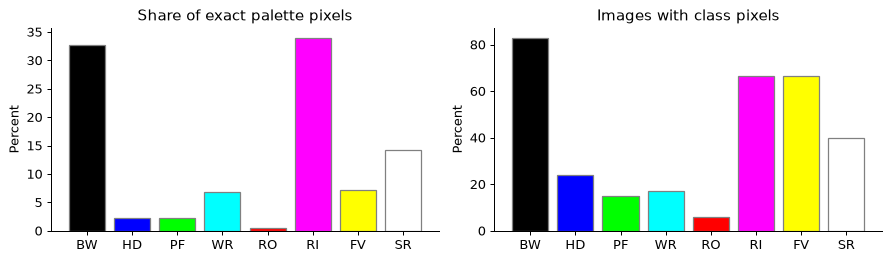

In [4]:
class_table = pd.DataFrame({'class': SYMBOLS, 'label': LABELS})
class_table['pixel_count'] = pixel_counts.sum(axis=0)
class_table['pixel_share_pct'] = 100 * class_table.pixel_count / pixel_counts.sum()
class_table['images_present'] = (pixel_counts > 0).sum(axis=0)
class_table['image_prevalence_pct'] = 100 * class_table.images_present / len(stats)
display(class_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, column, title in [(axes[0], 'pixel_share_pct', 'Share of exact palette pixels'),
                          (axes[1], 'image_prevalence_pct', 'Images with class pixels')]:
    ax.bar(SYMBOLS, class_table[column], color=PALETTE / 255, edgecolor='gray')
    ax.set(title=title, ylabel='Percent')
fig.tight_layout()
plt.show()

## Images, masks, and overlays

Show one corrected pair, one robot example, and two seeded random examples.
Cropping happens before display resizing; masks use nearest-neighbor resizing.

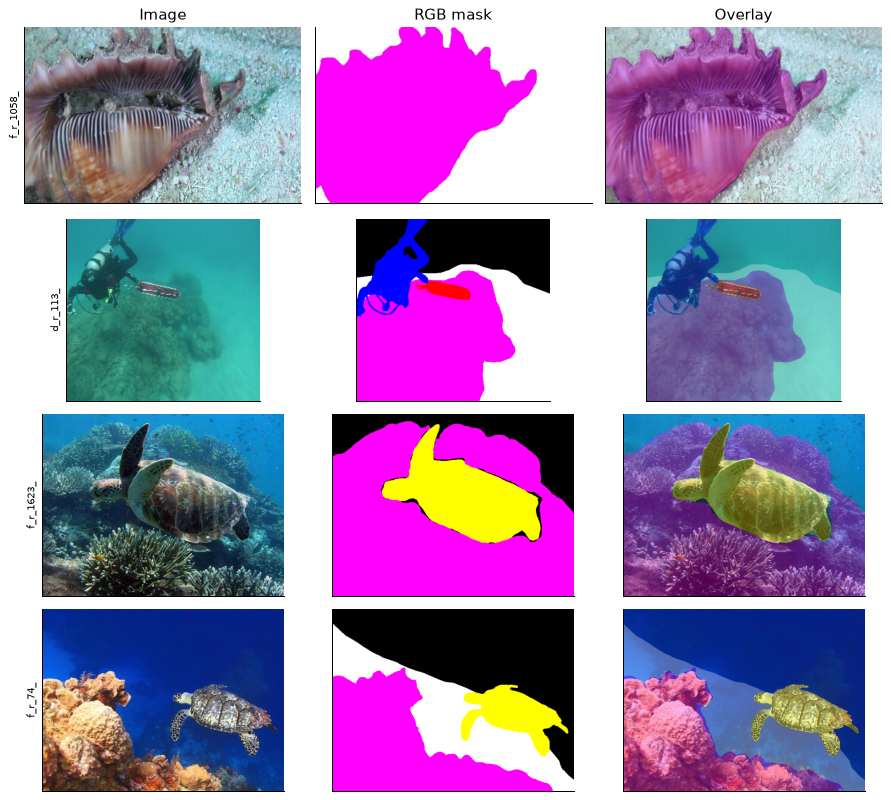

In [5]:
selected = [stats.loc[stats.mask_rows_cropped > 0, 'stem'].iloc[0],
            stats.loc[stats.pixels_RO > 0, 'stem'].iloc[0]]
selected += stats.loc[~stats.stem.isin(selected)].sample(2, random_state=SEED).stem.tolist()
fig, axes = plt.subplots(len(selected), 3, figsize=(10, 9))
for row, stem in enumerate(selected):
    image, mask = load_aligned_pair(data.images[stem], data.masks[stem],
                                    sample_id=f'train_val/{stem}')
    image.thumbnail((640, 640))
    rgb = np.asarray(mask.resize(image.size, Image.Resampling.NEAREST))
    alpha = np.any(rgb != 0, axis=-1).astype(float) * 0.3
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(rgb)
    axes[row, 2].imshow(image)
    axes[row, 2].imshow(np.dstack([rgb / 255.0, alpha]))
    axes[row, 0].set_ylabel(stem, fontsize=8)
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
for ax, title in zip(axes[0], ['Image', 'RGB mask', 'Overlay']):
    ax.set_title(title)
fig.tight_layout()
plt.show()

## Duplicates and saved results

SHA-256 detects identical image files. Keep duplicate groups in the same
training/validation partition. This check does not detect nearby video frames
or re-encoded copies. Reports are saved for later split design and training.

In [6]:
groups = stats.groupby('image_sha256').stem.agg(list)
groups = groups[groups.map(len) > 1]
duplicates = groups.rename('stems').reset_index()
duplicates['images'] = duplicates.stems.map(len)

def same_raw_masks(stems):
    arrays = []
    for stem in stems:
        with Image.open(data.masks[stem]) as mask:
            arrays.append(np.array(mask.convert('RGB')))
    return all(np.array_equal(arrays[0], a) for a in arrays[1:])

duplicates['mask_annotations_identical'] = duplicates.stems.map(same_raw_masks)
print(f'{len(duplicates)} duplicate image groups; {int(duplicates.images.sum())} images.')
display(duplicates[['stems', 'mask_annotations_identical']])

stats.to_csv(OUTPUT / 'train_val_image_stats.csv', index=False)
class_table.to_csv(OUTPUT / 'class_distribution.csv', index=False)
inventory.to_csv(OUTPUT / 'inventory.csv', index=False)
duplicates.to_csv(OUTPUT / 'exact_duplicate_groups.csv', index=False)
crops = stats.loc[stats.mask_rows_cropped > 0,
                  ['stem', 'width', 'height', 'raw_mask_width', 'raw_mask_height', 'mask_rows_cropped']]
crops.rename(columns={'width': 'image_width', 'height': 'image_height',
                      'raw_mask_width': 'mask_width', 'raw_mask_height': 'mask_height',
                      'mask_rows_cropped': 'height_difference'}).to_csv(OUTPUT / 'dimension_mismatches.csv', index=False)
summary = {**quality, 'python_executable': sys.executable, 'python_version': sys.version.split()[0],
           'test_pairs_inventory_only': len(test_inventory), 'exact_duplicate_groups': len(duplicates),
           'images_in_duplicate_groups': int(duplicates.images.sum()),
           'protocol': 'Eight classes after reviewed bottom crops; exact palette pixels only; TEST inventory only.'}
(OUTPUT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Reports: {OUTPUT.relative_to(ROOT)}')

9 duplicate image groups; 18 images.


,stems,mask_annotations_identical
0,"[f_r_1525_, f_r_816_]",False
1,"[f_r_192_, n_l_86_]",False
2,"[f_r_1672_, f_r_1995_]",False
3,"[f_r_26_, n_l_108_]",False
4,"[f_r_1913_, f_r_691_]",False
5,"[f_r_1196_, f_r_1647_]",False
6,"[d_r_622_, n_l_55_]",False
7,"[d_r_527_, n_l_27_]",False
8,"[d_r_668_, w_r_2_]",False


Reports: artifacts\suim_eda
